# Task 3
The previous problem should next be adjusted to include a constraint on the
exact number of items that need to be selected for the knapsack (e.g., each
individual has exactly 10 items, not more, not less). Assume that no population
member or offspring may violate the constraint on the exact number of items.
The following tasks should be considered:

## Setup

In [213]:
import random
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd

SEED = 22040 # Fixed number for the RNG to ensure reproducability.
random.seed(SEED)
np.random.seed(SEED)

# loading Data
df = pd.read_csv('../data/data_1001.csv')
item_values = df["Value"].to_list()
item_weights = df["Weight"].to_list()


# Loading test data
test_df = pd.read_csv('../data/data_31.csv')
test_item_values = test_df["Value"].to_list()
test_item_weights = test_df["Weight"].to_list()


## Functions from Task 1 and Task 2

### Task 1 functions (that did not need to be fixed)

In [214]:
# Survivor Selection Function:
# (Inputs: Individuals, Offspring, Fitness Individuals, Fitness Offspring;
# Outputs: (New) population). 
def survivor_selection( individuals: list[list[int]], offspring: list[list[int]],
                        fitness_individuals: list[float], fitness_offspring: list[float]) -> list[list[int]]:
    """Selects survivors based on the highest fitness values from the pooled population individuals and offspring. """
    combined = individuals + offspring
    combined_fitness = fitness_individuals + fitness_offspring
    fitness_ordered = np.argsort(combined_fitness)[::-1]

    return  [combined[i] for i in fitness_ordered[:len(individuals)]] 

### Task 2 functions (that did not need to be fixed)

In [215]:
# using dotproduct to find fitness
def fitness (individuals: list[list[int]], values: list[int]) -> list[int]:
    """
    Calculate the fitness of each individual in the population.

    An individual's fitness is the total value of the items it selects,
    computed as the dot product of its genes and the item values.

    Args:
        individuals: list of individuals in the population
        values: list of item values
    
    Returns:
        A list with one fitness score per individual.
    
    Example:
        >>> fitness([[0,1,1],[1,1,0]], [200,100,50])
        [150, 300]
    """
    #value_list = [None] * len(individuals)
    
    #for index in range(len(individuals)):
    #    value_list[index] = np.dot(individuals[index], values)
    #
    #return value_list

    return (np.array(individuals) @ np.array(values)).tolist()


def simple_genetic_algorithm(
    population_size, number_iter,
    crossover_prob, mutation_prob,
    value_list
    ) -> tuple[list[float], list[float], list[list[int], list[float]]]:
    """
    SGA for Task 2

    Returns:
        A list with 4 items.
        * avg_fitness_data
        * best_fitness_data
        * population
        * fitness_values
    """
    # To keep track of avg and best fitness across iterations
    avg_fitness_data, best_fitness_data = [], []
    # curr_avg_fit, curr_best_fit = 0.0, 0.0
    
    gene_len = len(value_list)
    population = initialization_knapsack(
        pop_size=population_size,
        num_bits=gene_len
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, value_list)


        new_avg_fitness = np.mean(fitness_values)
        avg_fitness_data.append(new_avg_fitness)

        new_best_fitness = np.max(fitness_values)
        best_fitness_data.append(new_best_fitness)

        # if new_best_fitness > curr_best_fit:
        #    curr_best_fit = new_best_fitness

        parents = parent_selection(population, fitness_values)

        offspring = one_point_crossover(parents, crossover_prob)
        offspring = mutation(offspring, mutation_prob)
        offspring_fitness_values = fitness(offspring, value_list)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return avg_fitness_data, best_fitness_data, population, fitness(population, value_list)

### Test helper functions

In [216]:
def test_structure(population: list[int]):
    print("Printing Individuals")
    print(f"num{"":>5}| {"0 count":<} | {"1 count":<} | only (1/0) | {"Item indexes":<41} | ")
    for num, ind in enumerate(population):
        ones  = ind.count(1)
        zeros = ind.count(0)
        only_binary = (ones + zeros == len(ind))

        arr_individual = np.array(ind)
        selected_positions   = np.where(arr_individual == 1)[0]

        print(f"{num+1:<8}| {zeros:<7} | {ones:<7} | {only_binary:<10} | {selected_positions} | ")
    
    print()
    all_binary = all(ind.count(0) + ind.count(1) == len(ind) for ind in population)
    print(f"All individuals contain only 0s and 1s: {all_binary}")

### New parent selection

In [217]:
# Parent Selection Function: 
# (Inputs: Individuals, Fitness values;
# Output: Parents (in random order, same number as individuals)). 
def parent_selection_task_3( individuals: list[list[int]], fitness_values: list[float] ) -> list[list[int]]:
    """Perform fitness-proportional parent selection such that more fit parents have a higher probability to be selected. """
    fitness = np.array(fitness_values, dtype=float)

    if fitness.min() < 0:
        fitness = fitness - fitness.min() + 1e-6   # shift so the minimum is just above 0

    if fitness.sum() == 0:
        probs = np.full(len(fitness), 1 / len(fitness))   # all equal: uniform selection
    else:
        probs = fitness / fitness.sum()

    idx = np.random.choice(len(individuals), size=len(individuals), replace=True, p=probs)
    return [individuals[i] for i in idx]

## Subtask 1
Discuss which functions of the SGA (i.e., initialization, fitness, parent se-
lection, recombination, mutation, survivor selection) need to be updated
so that the constraint on the exact number of items is not violated by any
population member or offspring. Comment for each whether it needs to
be updated, why the original function version will or may lead to a vio-
lation of the constraint and how it could be updated (Note: Full-point
solutions must satisfy the constraint immediately after recom-
bination and immediately after mutation, without first creating
invalid offspring. Solutions that temporarily create invalid off-
spring e.g., by using bitflip (as in task 2), and subsequently repair
them (e.g., at random or otherwise) are acceptable but will not
receive full points.).

### Written part

#### **Thoughts** (REMOVE LATER)
Maybe create a swap function: import never let any bit leave only swap them.

most likely slow down is mutation function.

For each function, the report needs three things: does it need updating, why the original version breaks (or doesn’t break) the constraint, and how you’d update it.

#### **Initialization:** 
The initialization functions needs to be updated, since in task to it selects at random about half of the bits to be turned on. This would break the rule of only ever having k bits turned on (k items selected). How to fix: first create the gene list with how ever many items there are, all elements in that list set to **zero**. Then we can use the handy **np.random.choice()** function from numpy with replacements set to false.  **np.random.choice(size_of_gene_list=1001, size=k, replace=False)**, this would select k random indexes in the list we can then set to be a **One**, the replace=False guarantees that the same index can not be selected twice.

#### **Fitness:**
The fitness function does not need to be changed since the only thing it does is calculate the fitness score of an individual, it never changes anything in that individual.

#### **Parent Selection:**
The parent selection function does not need to be changed since the only thing it does is copy the fittest individuals in a given population, so if we can guarantee that all of the individuals in the population have only k items selected, then there is no need to change the parent selection function

#### **Recombination:**
The recombination function does need to changed, since when the recombination function performs 1-point crossover it can break the guarantee that each gene can only have k values e.g., if we cut each parent in the middle, and say each has 5 items on both sides then the guarantee still holds. 

But say with k = 3:.
* Parent A: [0, 0, 0, 1, 1, 1] = 3 items (ok)
* Parent B: [1, 0, 1, 0, 1, 0] = 3 items (ok)

Then we cut after position 2
* Child A: [0, 0 | 1, 0, 1, 0] = 2 items (not ok)
* Child B: [1, 0 | 0, 1, 1, 1] = 4 items (not ok)

How we solve the problem?.
We start by sorting items into one of three groups:
1. Both parents picked item.
2. Only one of them picked that that item.
3. Neither parent picked that item.

How the child picks from those two parents:
* Keeps all items in group 1, since both parent chose it.
* Skips all items in group 3, since neither parent chose it.
* Then the child fills the remaining slots with random picks from group 2.

This guarantees the children of two parents always fulfils the guarantee of exactly k items.

#### **Mutation:**
The mutation function needs to be changed, the function right now goes through the gene list and has some probability to change (bit flip) each entry of gene. That would break the constraint on exactly k number of items, so there needs to be a way to guarantee that when we have a entry flip some other entry in the gene flips the oppsite way e.g., entry number 27 flips from 1 to 0.

The solution we are going with: For each of the k selected items, with probability PM, swap it with a random unselected item. Why go with this solution it? It makes the algorithm run alot, Instead of iterating over each gene of every individual. We simply iterate k times and have PM probability to swap that with a random unselected item.

then the mutation functions needs to make sure that some entry with 0 flips to 1, it does that by randomly selecting a entry that is a zreo. That way we make sure that the the constraint of exactly k items is always fulfilled.


#### **Mutation:**
The mutation function needs to be updated. The original version goes through every gene of an individual and, with probability PM, flips it (0 → 1 or 1 → 0). Each flip changes the number of selected items by one, so after mutation an individual will almost never have exactly k items, which breaks the constraint. To keep the count fixed, every flip from 1 to 0 must be paired with a flip from 0 to 1, e.g. if gene 27 flips from 1 to 0, some other gene that is currently 0 must flip to 1.

**Our solution (swap mutation):** For each of the k selected items, with probability PM, the item is swapped with a randomly chosen unselected item. Each swap removes exactly one item and adds exactly one, so the individual has exactly k selected items after every single swap. No invalid offspring is ever created and no repair step is needed.

**Why this approach:** It mirrors the original bit-flip mutation ("each gene gets a chance to mutate with probability PM"), but only iterates over the k selected genes instead of all genes, which makes it faster, especially for small k. The expected number of swaps per individual is k × PM, so mutation strength grows with k (e.g. = 1 swap for k = 10, = 80 swaps for k = 802 with PM = 0.1).

**Edge case:** When k equals the total number of items (k = 1001), there are no unselected items to swap with, so mutation has no effect. This is expected, since only one valid solution exists in that case.

#### **Survivor Selection:**
The survivor selection function does not need to be changed, for the same reason we don't need to change parent selection function as long as we guarantee a population that follows the constraint it cannot change any gene in the population.

### Fixing the broken functions

#### Initialization

In [218]:
def initialization_knapsack_task_3( pop_size: int, gene_len: int, k_items: int) -> list[list[int]]:
    """
    This function creates the individuals for the population, each having gene_len genes. 

    Args:
        pop_size: size of the population.
        gene_len: how long the gene is.
        gene_limit: how many entries in the gene can be 1.
    
    Returns:
      A list of `pop_size` individuals, each a list of `gene_len` ints (0 or 1), 
      with a limit of 1 based on gene_limit.
    
    Example:
        >>> initialization_knapsack(pop_size=3, gene_len=4, gene_limit=1)
        [[0, 1, 0, 0], [1, 0, 0, 0], [0, 1, 0, 0]]
    """
    
    population = []

    for _ in range(pop_size):        
        individual = np.zeros(gene_len, dtype=int) 
        chosen = np.random.choice(gene_len, size=k_items, replace=False)
        individual[chosen] = 1
        
        population.append(individual.tolist())
    
    return population

##### Testing initialization_knapsack_task_3 (TODO: move to subtask 2)

In [219]:
def test_initialization_knapsack_task_3():
    population_size = 5
    gene_len        = len(item_values)
    items_allowed   = 10

    population = initialization_knapsack_task_3(
        pop_size=population_size,
        gene_len=gene_len,
        gene_limit=items_allowed)

    print("Testing population size: expected 5")
    if len(population) == 5:
        print("CORRECT")
        print("population size: ", len(population))
    else:
        print("INCORRECT")

    print()

    print("Testing individual lenght: expected 1001")
    individual_1 = population[0]
    if len(individual_1) == 1001:
        print("CORRECT")
        print("individual size: ", len(individual_1))
    else:
        print("INCORRECT")
        print("individual size: ", len(individual_1))

    print()

    test_structure(population)

test_initialization_knapsack_task_3()

TypeError: initialization_knapsack_task_3() got an unexpected keyword argument 'gene_limit'

#### Recombination

In [ ]:
def make_children(parent_a: list[int], parent_b: list[int], k_items) -> tuple[list[int], list[int]]:
    #build child
    arr_parent_1 = np.array(parent_a)
    arr_parent_2 = np.array(parent_b)

    selected_p1 = arr_parent_1 == 1
    selected_p2 = arr_parent_2 == 1

    # Both parents picket the item
    group_1 = selected_p1 & selected_p2
    # Exactly one parent picket the item
    group_2 = selected_p1 ^ selected_p2

    k = arr_parent_1.sum()                   # every parent has exactly k items
    needed = k - group_1.sum()               # items each child needs from group 2

    group_2_positions = np.where(group_2)[0]

    # Child 1 takes a random half of group 2, child 2 takes the other half
    child_1_share = np.random.choice(group_2_positions, size=needed, replace=False)
    child_2_share = np.setdiff1d(group_2_positions, child_1_share)

    child_1 = np.zeros(len(parent_a), dtype=int)
    child_2 = np.zeros(len(parent_a), dtype=int)

    child_1[group_1] = 1
    child_2[group_1] = 1
    child_1[child_1_share] = 1
    child_2[child_2_share] = 1

    return child_1.tolist(), child_2.tolist()



def crossover_task_3( parents: list[list[int]], crossover_prob: float, k_items: int ) -> list[list[int]]:
    offspring = []

    for i in range(0, len(parents) - 1, 2):
        parent_a, parent_b = parents[i], parents[i + 1]

        if np.random.uniform(0, 1) <= crossover_prob:
            child_1, child_2 = make_children(parent_a, parent_b, k_items)
        else:
            child_1, child_2 = parent_a.copy(), parent_b.copy()

        offspring.append(child_1)
        offspring.append(child_2)

    if len(parents) % 2 == 1:
        offspring.append(parents[-1].copy())

    return offspring


##### Testing crossover_task_3 (TODO: move to subtask 2)

In [ ]:
k_items = 3
a = [1, 1, 0, 1, 0, 0]
b = [1, 0, 1, 0, 1, 0]

c1, c2 = make_children(a, b, k_items)
print("Parent A:", a, "| Parent B:", b)
print("Child 1: ", c1, "| items:", sum(c1))
print("Child 2: ", c2, "| items:", sum(c2))

print("test 2 =============")

pop_size = 50
gene_len = 1001 
k_items  = 400

pop = initialization_knapsack_task_3(pop_size, gene_len, k_items)

pm_1 = 1.0
children = crossover_task_3(pop, pm_1, k_items)
print("All exactly k after crossover:", all(sum(c) == 400 for c in children))

pm_2 = 0.0
copies = crossover_task_3(pop, pm_2, k_items )
print("PC = 0 copies parents:", copies == pop)

same_1, same_2 = make_children(pop[0], pop[0], k_items)
print("Identical parents give copies:", same_1 == pop[0] and same_2 == pop[0])

Parent A: [1, 1, 0, 1, 0, 0] | Parent B: [1, 0, 1, 0, 1, 0]
Child 1:  [1, 0, 1, 1, 0, 0] | items: 3
Child 2:  [1, 1, 0, 0, 1, 0] | items: 3
test 2 =============
All exactly k after crossover: True
PC = 0 copies parents: True
Identical parents give copies: True


#### Mutation

In [ ]:
def mutation_task_3( individuals: list[list[int]], mutation_prob: float, k_items: int ) -> list[list[int]]:
    """ meow """
    # return if lenght of gene is the same as item limit
    # If every item must be selected, no swap is possible: return copies unchanged
    if len(individuals[0]) == k_items:
        return [individual.copy() for individual in individuals]

    mutated = []

    for individual in individuals:
        offspring = individual.copy()

        # Snapshot of the originally selected positions
        selected_positions = np.where(np.array(individual) == 1)[0]

        for index in selected_positions:
            if np.random.uniform(0, 1) <= mutation_prob:
                # Recompute from the CURRENT offspring so the list is never stale
                unselected_positions = np.where(np.array(offspring) == 0)[0]
                swap_index = np.random.choice(unselected_positions)

                # Swap: remove one item, add one item
                offspring[index] = 0
                offspring[swap_index] = 1

        mutated.append(offspring)

    return mutated

##### Testing mutation_task_3 (TODO: move to subtask 2)

In [ ]:
def test_mutation_task_3():
    items_allowed   = 10 # k
    population_size = 5
    gene_len        = len(item_values)
    pm              = 0.1

    pop = initialization_knapsack_task_3(population_size, gene_len, items_allowed)
    print("Before mutation ========================")
    test_structure(pop)

    print()

    new_pop = mutation_task_3(pop, pm, k_items=items_allowed)
    print("After mutation ========================")
    test_structure(new_pop)

    print("break k constraint")
    print()
    for cnt, indv in enumerate(new_pop):
        print(f"Individual {cnt} =================")
        one_cnt = indv.count(1)
        if one_cnt != items_allowed:
            print(f"Wrong: One count: {one_cnt} != {items_allowed}")
        else:
            print(f"Correct: One count: {one_cnt} == {items_allowed}")

test_mutation_task_3()

Before mutation ========================
Printing Individuals
num     | 0 count | 1 count | only (1/0) | Item indexes                              | 
1       | 991     | 10      | 1          | [291 605 615 702 742 840 854 874 882 982] | 
2       | 991     | 10      | 1          | [281 354 384 450 668 810 858 907 952 961] | 
3       | 991     | 10      | 1          | [ 37  59 100 211 364 572 641 651 677 775] | 
4       | 991     | 10      | 1          | [338 400 415 554 625 735 739 747 948 964] | 
5       | 991     | 10      | 1          | [101 133 221 473 516 528 689 744 946 978] | 

All individuals contain only 0s and 1s: True

After mutation ========================
Printing Individuals
num     | 0 count | 1 count | only (1/0) | Item indexes                              | 
1       | 991     | 10      | 1          | [167 291 605 615 702 742 854 874 882 982] | 
2       | 991     | 10      | 1          | [354 450 451 542 668 707 810 858 952 961] | 
3       | 991     | 10      | 1       

In [ ]:
pop = initialization_knapsack_task_3(50, 1001, 400)

mutated = mutation_task_3(pop, 0.9, k_items=400)
print("All exactly k after heavy mutation:", all(sum(ind) == 400 for ind in mutated))

unchanged = mutation_task_3(pop, 0.0, k_items=400)
print("PM = 0 leaves individuals unchanged:", unchanged == pop)

All exactly k after heavy mutation: True
PM = 0 leaves individuals unchanged: True


## Subtask 2
ccording to the answer above, create the updated functions for the SGA
(Note: briefly check for each updated function with a simple example that
it performs as intended). Run the algorithm for at least the following
exact number of items [1001, 802, 400, 100, 10] and record (1) the fitness,
(2) number of items, and (3) average value per selected item (i.e., fitness /
number of items). Comment on how the number of items in the constraint
affects the fitness and the average value per selected item.

### Simple Genetic Algorithm

In [ ]:
def simple_genetic_algorithm_task_3(
    population_size: int, number_iter: int,
    crossover_prob: float, mutation_prob: float,
    value_list: list, k_items: int
    ) -> tuple[list[float], list[float], list[list[int], list[float]]]:
    """
    SGA for Task 3

    Returns:
        A list with 4 items.
        * avg_fitness_data
        * best_fitness_data
        * population
        * fitness_values
    """
    # To keep track of avg and best fitness across iterations
    avg_fitness_data, best_fitness_data = [], []
    # curr_avg_fit, curr_best_fit = 0.0, 0.0
    
    gene_len = len(value_list)
    population = initialization_knapsack_task_3(
        pop_size=population_size,
        gene_len=gene_len,
        k_items=k_items
    )

    for _ in range(number_iter):
        fitness_values = fitness(population, value_list)


        new_avg_fitness = np.mean(fitness_values)
        avg_fitness_data.append(new_avg_fitness)

        new_best_fitness = np.max(fitness_values)
        best_fitness_data.append(new_best_fitness)

        # if new_best_fitness > curr_best_fit:
        #    curr_best_fit = new_best_fitness

        parents = parent_selection_task_3(population, fitness_values)

        offspring = crossover_task_3(parents, crossover_prob, k_items)
        offspring = mutation_task_3(offspring, mutation_prob, k_items)
        offspring_fitness_values = fitness(offspring, value_list)

        survivors = survivor_selection(
            population,
            offspring,
            fitness_values,
            offspring_fitness_values
        )
        population = survivors

    return avg_fitness_data, best_fitness_data, population, fitness(population, value_list)

#### Testing simple_genetic_algorithm_task_3 (stats at end my be a bit weird)

Test with k = 1001
Population size: 30 | Iterations: 500 | PC: 0.9 | PM: 0.1
Average fitness of final population: 5,767,936.00
Best fitness of final population:    5,767,936
Number of items (best individual):   1001
Average value per selected item:     5,762.17
Optimum for k = 1001: 5,767,936 (100.00% reached)
All individuals have exactly k items: True

Test with k = 802
Population size: 30 | Iterations: 500 | PC: 0.9 | PM: 0.1
Average fitness of final population: 5,066,718.50
Best fitness of final population:    5,093,348
Number of items (best individual):   802
Average value per selected item:     6,350.81
Optimum for k = 802: 6,231,819 (81.73% reached)
All individuals have exactly k items: True



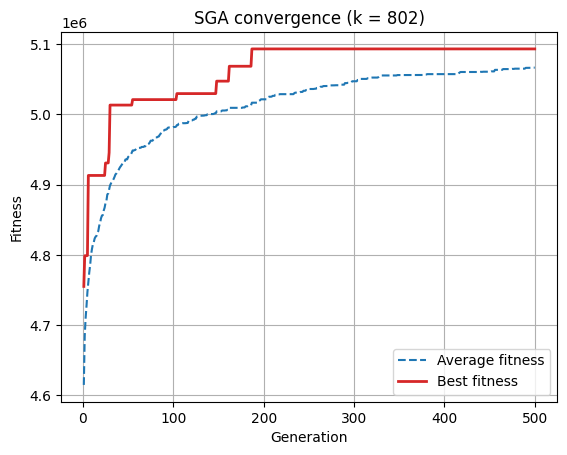

Test with k = 400
Population size: 30 | Iterations: 500 | PC: 0.9 | PM: 0.1
Average fitness of final population: 3,348,078.20
Best fitness of final population:    3,417,931
Number of items (best individual):   400
Average value per selected item:     8,544.83
Optimum for k = 400: 4,682,804 (72.99% reached)
All individuals have exactly k items: True

Test with k = 100
Population size: 30 | Iterations: 500 | PC: 0.9 | PM: 0.1
Average fitness of final population: 1,260,792.97
Best fitness of final population:    1,285,026
Number of items (best individual):   100
Average value per selected item:     12,850.26
Optimum for k = 100: 1,477,370 (86.98% reached)
All individuals have exactly k items: True

Test with k = 10
Population size: 30 | Iterations: 500 | PC: 0.9 | PM: 0.1
Average fitness of final population: 165,581.00
Best fitness of final population:    165,581
Number of items (best individual):   10
Average value per selected item:     16,558.10
Optimum for k = 10: 165,903 (99.81% reac

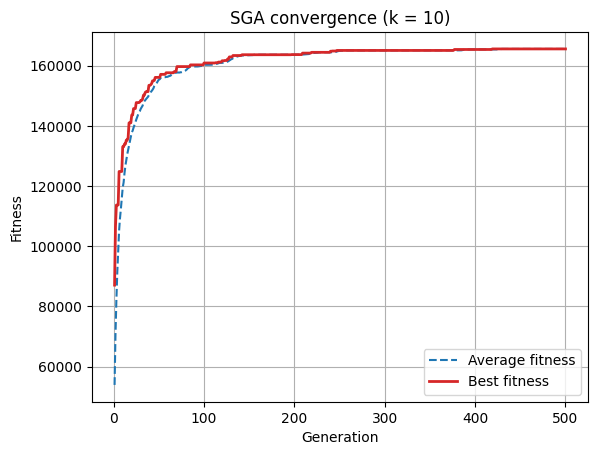

   k  Best fitness  Number of items  Avg value per item  Optimum  % of optimum  Constraint held
1001       5767936             1001             5762.17  5767936        100.00             True
 802       5093348              802             6350.81  6231819         81.73             True
 400       3417931              400             8544.83  4682804         72.99             True
 100       1285026              100            12850.26  1477370         86.98             True
  10        165581               10            16558.10   165903         99.81             True


In [240]:
def plot_fitness_data(avg_fitness_data: list[float], best_fitness_data: list[float], k_items: int):
    gens = range(1, len(avg_fitness_data) + 1)

    plt.plot(gens, avg_fitness_data, color="tab:blue", linestyle="--", label="Average fitness")
    plt.plot(gens, best_fitness_data, color="tab:red", linestyle="-", linewidth=2, label="Best fitness")
    plt.xlabel("Generation")
    plt.ylabel("Fitness")
    plt.title(f"SGA convergence (k = {k_items})")
    plt.legend()
    plt.grid(True)
    plt.show()


def test_sga_task_3(k_items: int, pop_size: int = 30, num_iter: int = 500,
                    pc: float = 0.9, pm: float = 0.1, show_plot: bool = False) -> dict:
    report = simple_genetic_algorithm_task_3(
        population_size=pop_size,
        number_iter=num_iter,
        crossover_prob=pc,
        mutation_prob=pm,
        value_list=item_values,
        k_items=k_items
    )

    avg_fitness_data, best_fitness_data, population, population_fitness = report

    # Best individual of the final population
    best_index      = np.argmax(population_fitness)
    best_individual = population[best_index]
    best_fitness    = population_fitness[best_index]
    num_items       = sum(best_individual)

    # Constraint check on the whole final population
    all_exactly_k = all(sum(ind) == k_items for ind in population)

    # Optimum for exact-k: the k highest-value items
    optimum = np.sort(item_values)[-k_items:].sum()

    print("=" * 60)
    print(f"Test with k = {k_items}")
    print(f"Population size: {pop_size} | Iterations: {num_iter} | PC: {pc} | PM: {pm}")
    print(f"Average fitness of final population: {np.mean(population_fitness):,.2f}")
    print(f"Best fitness of final population:    {best_fitness:,}")
    print(f"Number of items (best individual):   {num_items}")
    print(f"Average value per selected item:     {best_fitness / num_items:,.2f}")
    print(f"Optimum for k = {k_items}: {optimum:,} ({best_fitness / optimum * 100:.2f}% reached)")
    print(f"All individuals have exactly k items: {all_exactly_k}")
    print("=" * 60 + "\n")

    if show_plot:
        plot_fitness_data(avg_fitness_data, best_fitness_data, k_items)

    return {
        "k": k_items,
        "Best fitness": best_fitness,
        "Number of items": num_items,
        "Avg value per item": round(best_fitness / num_items, 2),
        "Optimum": optimum,
        "% of optimum": round(best_fitness / optimum * 100, 2),
        "Constraint held": all_exactly_k,
    }


k_values = [1001, 802, 400, 100, 10]

results = []
for k in k_values:
    results.append(test_sga_task_3(k, show_plot=(k in [802, 10])))

results_table = pd.DataFrame(results)
print(results_table.to_string(index=False))

### Commenting on the results
Comment on how the number of items in the constraint
affects the fitness and the average value per selected item.

# what is left
task 2 subtask 5

task 3 subtask 2 writing and subtask 3 and 4